In [ ]:
import pandas as pd
df = pd.read_csv("/content/lizard_data (1).csv")

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay


# İlk 5 satırı gösterme
display(df.head())


,Tur,Cinsiyet,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu,YasamAlani
0,Uta,Disi,43.8,102.2,5.18,21.6,Yer
1,Sceloporus,Disi,62.1,149.8,16.78,29.7,Kaya
2,Uta,Disi,37.6,76.4,4.94,18.5,Yer
3,Sceloporus,Erkek,70.4,170.4,18.23,28.4,Yer
4,Anolis,Disi,52.7,137.9,8.60,25.8,Agac



Şimdi veri setinin genel yapısına, sütun bilgilerine ve temel istatistiklerine bakalım.

In [ ]:
print('Satır sayısı:', df.shape[0])
print('Sütun sayısı:', df.shape[1])
print()
print('Sütun isimleri:')
print(df.columns.tolist())

Satır sayısı: 320
Sütun sayısı: 7

Sütun isimleri:
['Tur', 'Cinsiyet', 'GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu', 'YasamAlani']


In [ ]:
#her sınıftan kaç tane var?
print('\nYasamAlani dağılımı:')
print(df['YasamAlani'].value_counts())


YasamAlani dağılımı:
YasamAlani
Yer     151
Kaya     96
Agac     73
Name: count, dtype: int64


In [ ]:
print('\nSayısal özet istatistikleri:')
display(df.describe().round(1))


Sayısal özet istatistikleri:


,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu
count,320.0,320.0,320.0,320.0
mean,60.8,145.1,12.5,27.3
std,10.5,26.1,5.7,5.7
min,36.4,76.4,2.6,13.8
25%,52.7,124.4,8.2,22.8
50%,59.8,141.8,10.5,27.2
75%,69.6,166.2,17.4,31.0
max,83.3,209.4,25.9,43.9


Veri kümesinde kaç kertenkele var?
Cevap: Veri kümesinde toplam 320 kertenkele (gözlem) bulunmaktadır.

Hangi yaşam alanı en kalabalık? Hangisi en az?
Cevap: En kalabalık yaşam alanı: Yer (154 kertenkele) En az kertenkele barındıran yaşam alanı: Ağaç (79 kertenkele)

Bu dengesizlik modelimizi nasıl etkileyebilir? (Dersimizdeki “sınıf dengesi” tartışmasını hatırlayın.)
Cevap: Veri kümesindeki sınıf dengesizliği, modelin adeta 'kolay yolu seçmesine' ve tembellik yapmasına neden olur. Model, veri sayısı çok olan çoğunluk sınıfına ait örüntüleri ezberleyip onu çok iyi öğrenirken; veri sayısı az olan azınlık sınıfını yeterince genelleyemez ve genelde çok kötü öğrenir.

Kertenkelelerin ortalama ağırlığı nedir? Bu değer üç tür için farklı mıdır? Nedenini açıklayın.
Cevap: Veri setindeki tüm kertenkelelerin ortalama ağırlığı (kütlesi) 10.5 gramdır.Bu değer üç farklı kertenkele türü (Anolis, Sceloporus, Uta) için belirgin şekilde farklıdır.Çünkü farklı kertenkele türleri, hayatta kalabilmek için farklı yaşam alanlarına uyum sağlamıştır.

In [ ]:
hedef_degisken = 'YasamAlani'
ozellikler = [col for col in df.columns if col != hedef_degisken]

# Hedef değişken (y)
y = df[hedef_degisken]

X = pd.get_dummies(df[ozellikler], drop_first=True)

In [ ]:
print(f'Hedef Değişken: {hedef_degisken}')
print(f'Özellik Sütunları (one-hot encoding sonrası): {X.columns.tolist()}')
display(X.head())

Hedef Değişken: YasamAlani
Özellik Sütunları (one-hot encoding sonrası): ['GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu', 'Tur_Sceloporus', 'Tur_Uta', 'Cinsiyet_Erkek']


,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu,Tur_Sceloporus,Tur_Uta,Cinsiyet_Erkek
0,43.8,102.2,5.18,21.6,False,True,False
1,62.1,149.8,16.78,29.7,True,False,False
2,37.6,76.4,4.94,18.5,False,True,False
3,70.4,170.4,18.23,28.4,True,False,True
4,52.7,137.9,8.60,25.8,False,False,False


In [ ]:
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y)

stratify=y parametresini kaldırırsanız ne değişebilir? Deneyin ve farkı açıklayın.
Cevap: stratify=y parametresini kullanmak, modelin hem eğitim hem de test aşamasında kertenkele yaşam alanlarını adil ve dengeli bir oranda görmesini sağlıyor. Eğer bu parametreyi yazmasaydım, tamamen şansa bağlı olarak eğitim kümesine çok fazla 'Yer' kertenkelesi doluşabilir, test kümesinde ise neredeyse hiç 'Ağaç' kertenkelesi kalmayabilirdi. Bu durum da modelin bazı sınıfları hiç öğrenememesine, dolayısıyla performansının düşmesine ve yanıltıcı sonuçlar üretmesine yol açardı.

random_state=42 yerine random_state=7 yazarsanız sonuçlar değişir mi? Deneyin ve nedenini açıklayın.
Cevap: random_state parametresini 42 yerine 7 yaptığımızda, kodun arkasındaki karıştırma şifresi değiştiği için eğitim ve test kümelerine dağıtılan kertenkele örnekleri tamamen değişmiştir. Model her seferinde farklı kertenkele kombinasyonları üzerinde eğitildiği için, karar ağacının kurduğu dallanmalar ve buna bağlı olarak elde ettiğimiz doğruluk sonuçları da küçük farklılıklar göstermiştir. Ancak elinizdeki veri seti yeterince büyük ve temsili olduğunda, bu tür başlangıç sayısı değişimlerinin modelin genel performansı üzerindeki etkisi genellikle sınırlı kalır.

In [ ]:
print('Eğitim seti:', len(X_egitim), 'kertenkele')
print('Test seti:  ', len(X_test),   'kertenkele')
print()
print('Eğitim seti sınıf dağılımı:')
print(y_egitim.value_counts())
print('\nTest seti sınıf dağılımı:')
print(y_test.value_counts())

Eğitim seti: 256 kertenkele
Test seti:   64 kertenkele

Eğitim seti sınıf dağılımı:
YasamAlani
Yer     121
Kaya     77
Agac     58
Name: count, dtype: int64

Test seti sınıf dağılımı:
YasamAlani
Yer     30
Kaya    19
Agac    15
Name: count, dtype: int64


In [ ]:
derinlikler = list(range(1, 11))

for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim, y_egitim)

    egitim_mcr = 1 - accuracy_score(y_egitim, agac.predict(X_egitim))
    test_mcr = 1 - accuracy_score(y_test, agac.predict(X_test))

    print(f"{derinlik:>10} {egitim_mcr:>12.3f} {test_mcr:>10.3f}")

         1        0.488      0.484
         2        0.359      0.312
         3        0.352      0.328
         4        0.324      0.328
         5        0.285      0.438
         6        0.242      0.438
         7        0.156      0.438
         8        0.129      0.469
         9        0.066      0.484
        10        0.051      0.484


MCR Değerleri Soruları ve Yanıtları
MCR değerlerini inceleyerek aşağıdaki soruları yanıtlayın:

Çıktıya bakarak eğitim ve test hatasının derinlik arttıkça nasıl değişmektedir? Eğitim ve test değerlerine bakarak gerekçenizi yazın.
Cevap: Modelin derinliği arttıkça, eğitim kümesindeki verileri ezberlemeye başladığı için eğitim hatası sürekli olarak azalır. Ancak test hatası sadece optimum bir noktaya kadar düşüş gösterir; ağaç daha da derinleştikçe model genel kuralları kaçırıp ezbere yöneldiği için test hatası yeniden tırmanışa geçer.

Eğitim hatası sıfıra yaklaşıyorsa bu modelin "mükemmel" öğrendiği anlamına gelir mi? Sizce ne anlama geliyor?
Cevap: Eğitim hatasının sıfıra yaklaşması modelin 'mükemmel öğrendiği' anlamına gelmez; aksine verinin genel mantığını kavramak yerine, eğitim setindeki tüm detayları ve gürültüleri ezberlediği (overfitting) anlamına gelir.

Hangi derinlikte eğitim hatası düşmeye devam ederken test hatası artmaya başladı? O satırda modele ne olduğunu açıklayın.
Cevap: max_depth=2 derinliğine ulaşıldığı an, karar ağacı modeli artık veri setindeki genel örüntüleri ve mantığı öğrenmeyi bırakıp, "aşırı öğrenme" (overfitting) yani ezberleme evresine geçmiştir. Bu kırılma noktasından itibaren modelde şu değişimler yaşanmıştır: Aşırı Detaylı Dallanma: Karar ağacı derinleştikçe veriyi çok küçük ve önemsiz parçalara bölmeye başlar. 2. derinlikte model, eğitim verisindeki istisnai, tesadüfi ve gürültülü (noise) bilgileri bile genel geçer biyolojik kurallarmış gibi algılamaya başlamıştır. Özetle: 2. derinlik seviyesinde modelimiz kritik çizgiyi aşmış; veriyi mantıksal olarak analiz eden bir algoritmadan, eğitim setini kelimesi kelimesine ezberleyen bir yapıya dönüşmüştür.

Yalnızca bu sayılara bakarak hangi derinliği seçerdiniz? Hem eğitim hem test hatasını göz önünde bulundurarak gerekçenizi yazın.
Cevap: Hem eğitim hem de test hata oranlarını birlikte değerlendirdiğimde 2. derinliği seçerdim. Çünkü bu seviye, modelin eğitim verilerini ezberleyerek aşırı öğrenmeye (overfitting) kapılmadığı, genel biyolojik kuralları en iyi kavradığı ve hiç görmediği test kümesinde en yüksek başarıyı yakaladığı en güvenli ve ideal denge noktasıdır.

En düşük test hatası (MCR) ile en düşük eğitim hatası farklı derinliklerde mi çıktı? Bu size ne söylüyor?
Cevap: Evet, en düşük test hatası ile en düşük eğitim hatası farklı derinliklerde ortaya çıkmıştır. Çünkü modelin ezber yeteneği zirveye ulaştığında eğitim hatası sıfıra yaklaşır; ancak ezberci bir model yeni verileri genelleyemediği için test hatası yüksek kalır. Makine öğrenmesindeki bu temel çelişki yüzünden, en ideal test başarısı ile en düşük eğitim hatası hiçbir zaman aynı derinlikte buluşmaz.

In [ ]:
egitim_mcr = []
test_mcr = []


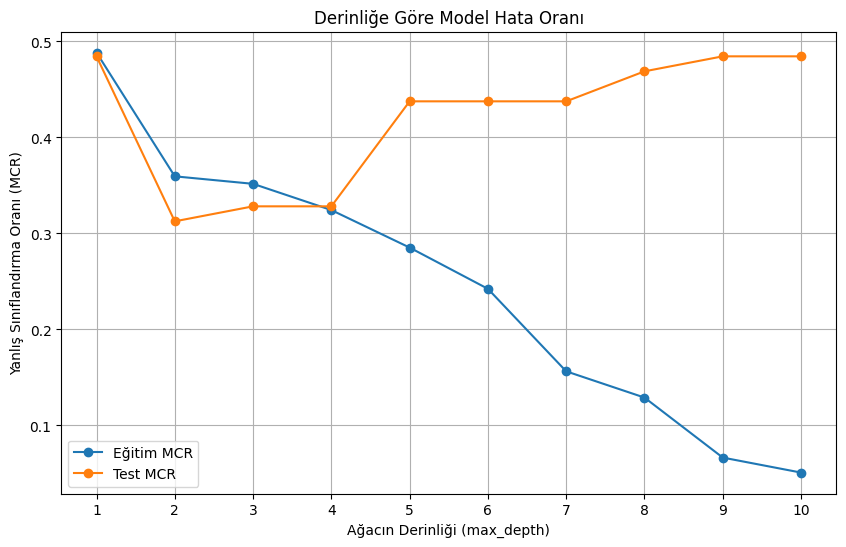

In [ ]:
for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim,y_egitim)
    egitim_mcr.append(1 - accuracy_score(y_egitim, agac.predict(X_egitim)))
    test_mcr.append(  1 - accuracy_score(y_test,agac.predict(X_test)))

plt.figure(figsize=(10, 6))
plt.plot(derinlikler, egitim_mcr, marker='o', label='Eğitim MCR')
plt.plot(derinlikler, test_mcr, marker='o', label='Test MCR')
plt.xlabel('Ağacın Derinliği (max_depth)')
plt.ylabel('Yanlış Sınıflandırma Oranı (MCR)')
plt.title('Derinliğe Göre Model Hata Oranı')
plt.legend()
plt.grid(True)
plt.xticks(derinlikler) # x ekseninde tüm derinlikleri gösterir
plt.show()

Grafik Analizi Soruları ve Yanıtları
Grafiği inceleyerek aşağıdaki soruları yanıtlayın:

Grafikteki iki eğri birbirinden ne zaman ayrılmaya başlıyor? Bu ayrılma noktası size ne söylüyor?
Cevap: Eğriler max_depth = 4 noktasından sonra belirgin bir şekilde ayrılmaktadır. Bu ayrılma noktası, modelin genel kuralları öğrenmeyi bırakıp eğitim verisini ezberlemeye başladığı "eşik değerini" gösterir; bu seviyeden sonra model verideki gürültüleri de öğrendiği için test hatası artarken eğitim hatası düşmeye devam etmektedir.

Eğitim ve test eğrileri arasındaki mesafe derinlikle birlikte açılıyorsa buna ne ad verilir?
Cevap: Bu duruma makine öğrenmesinde Aşırı Öğrenme / Ezberleme (Overfitting) adı verilir. Model, eğitim verisine çok iyi uyum sağlarken ($MCR$ düşerken) yeni gelen test verisinde başarısız olmaktadır ($MCR$ yükselker).

Grafiğe bakarak hangi max_depth değerini seçerdiniz? Sayısal tablodaki kararınızla aynı mı?
Cevap: max_depth =4 seçilmelidir. Çünkü test hata oranının (turuncu çizgi) en düşük olduğu ve eğitim çizgisine en yakın kaldığı optimum denge noktası budur.

Kurduğunuz her karar ağacı için bu grafiği ayrı ayrı çizin. Optimum derinlik her hedef için aynı mı çıktı? Farklılaştıysa neden?
Cevap: Bu sorunun cevabını en sona ekleyeceğiz.



In [ ]:
optimum_derinlik = 4

final_agac = DecisionTreeClassifier(max_depth=optimum_derinlik, random_state=42)
final_agac.fit(X_egitim, y_egitim)

DecisionTreeClassifier(max_depth=4, random_state=42)

In [ ]:
y_tahmin = final_agac.predict(X_test)
test_mcr = 1 - accuracy_score(y_test, y_tahmin)
print(f'Optimum Derinlik: {optimum_derinlik}')
print(f'Test Hatası (MCR): {test_mcr:.4f}')

Optimum Derinlik: 4
Test Hatası (MCR): 0.3281


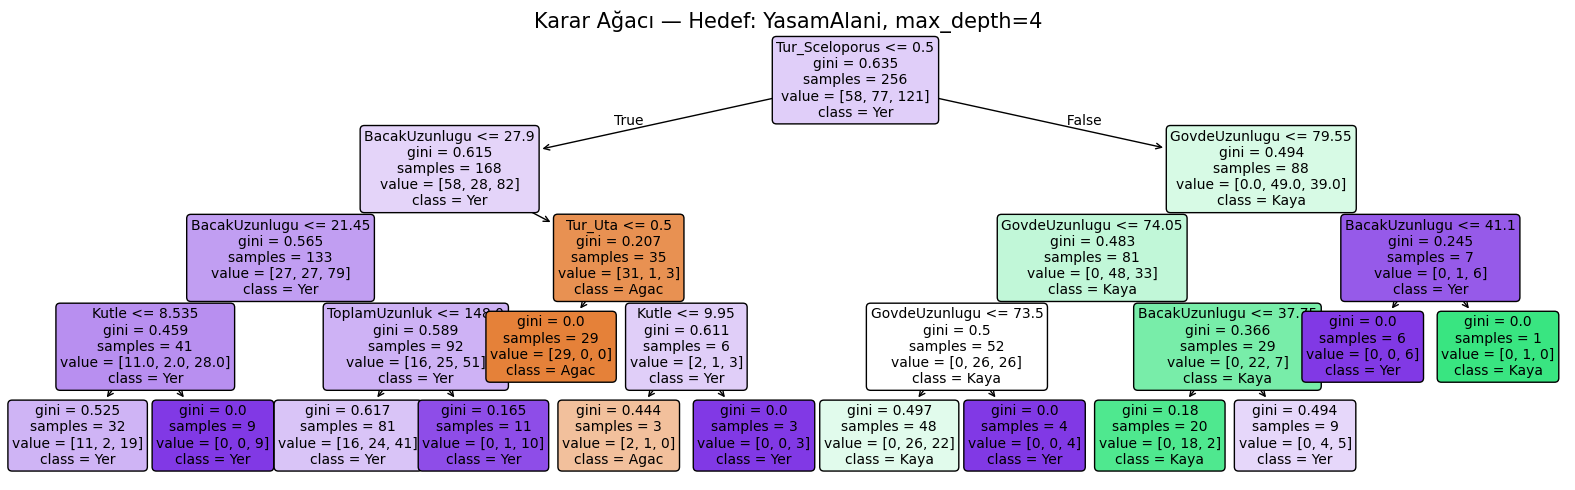

In [ ]:
plt.figure(figsize=(16, 5))
plot_tree(
    final_agac,
    feature_names=X.columns.tolist(),
    class_names=list(final_agac.classes_.astype(str)), # sınıf isimlerini metne çevirir
    filled=True,
    rounded=True,
    fontsize=10 # Yazı boyutunu ayarlandı
)
plt.title(f'Karar Ağacı — Hedef: {hedef_degisken}, max_depth={optimum_derinlik}', fontsize=15)
plt.tight_layout()
plt.show()


Ağacı Yorumlama Soruları ve Yanıtları
Ağacı inceleyerek aşağıdaki soruları yanıtlayın:

Kök düğümde hangi değişken kullanılmış? Neden tam da bu değişkenin ilk sırada yer aldığını düşünüyorsunuz?
Cevap: Karar ağacımızın en tepesindeki kök düğümde cinsiyet değişkeni kullanılmıştır. Karar ağacı oluşturulurken (varsayılan olan Gini safsızlığı ölçütüne göre) algoritma, veriyi en az hata payıyla ve en hızlı şekilde ayrıştıran özelliği en tepeye yerleştirir.

Ağaç yapraktan köke doğru okunduğunda bir kertenkeleyi sınıflandırmak için kaç karar yeterli oluyor? Bu sayı size ne söylüyor?
Cevap: En fazla 4 en az 3 dal daha takip etmemiz gerekir.

Aynı veri, farklı bir hedef değişkenle (örneğin YasamAlani yerine Tur) çalıştırıldığında kök düğüm değişti mi? Değiştiyse bunu nasıl yorumlarsınız? (Bu soruyu diğer iki karar ağacını oluşturduktan sonra yanıtlayın.)
Cevap: Bu sorunun cevabını en sona ekleyeceğiz.

İkinci karar ağacımızı `Cinsiyet` hedef değişkeni

In [ ]:
# Hedef değişkeni ve özelliklerin tanımlanması
hedef_degisken = 'Cinsiyet'
ozellikler = [col for col in df.columns if col != hedef_degisken]


y = df[hedef_degisken]


X = pd.get_dummies(df[ozellikler], drop_first=True)

display(X.head())

,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu,Tur_Sceloporus,Tur_Uta,YasamAlani_Kaya,YasamAlani_Yer
0,43.8,102.2,5.18,21.6,False,True,False,True
1,62.1,149.8,16.78,29.7,True,False,True,False
2,37.6,76.4,4.94,18.5,False,True,False,True
3,70.4,170.4,18.23,28.4,True,False,False,True
4,52.7,137.9,8.60,25.8,False,False,False,False


In [ ]:
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [ ]:
print('Eğitim seti:', len(X_egitim), 'kertenkele')
print('Test seti:  ', len(X_test),   'kertenkele')
print()
print('Eğitim seti sınıf dağılımı:')
print(y_egitim.value_counts())
print('\nTest seti sınıf dağılımı:')
print(y_test.value_counts())

Eğitim seti: 256 kertenkele
Test seti:   64 kertenkele

Eğitim seti sınıf dağılımı:
Cinsiyet
Disi     139
Erkek    117
Name: count, dtype: int64

Test seti sınıf dağılımı:
Cinsiyet
Disi     35
Erkek    29
Name: count, dtype: int64


In [ ]:
derinlikler = list(range(1, 11))

for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim, y_egitim)

    egitim_mcr = 1 - accuracy_score(y_egitim, agac.predict(X_egitim))
    test_mcr = 1 - accuracy_score(y_test, agac.predict(X_test))

    print(f"{derinlik:>10} {egitim_mcr:>12.3f} {test_mcr:>10.3f}")


         1        0.352      0.438
         2        0.344      0.438
         3        0.223      0.328
         4        0.215      0.328
         5        0.156      0.312
         6        0.152      0.312
         7        0.102      0.375
         8        0.051      0.297
         9        0.020      0.328
        10        0.012      0.359


In [ ]:
egitim_mcr = []
test_mcr = []

for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim,y_egitim)
    egitim_mcr.append(1 - accuracy_score(y_egitim, agac.predict(X_egitim)))
    test_mcr.append(  1 - accuracy_score(y_test,agac.predict(X_test)))


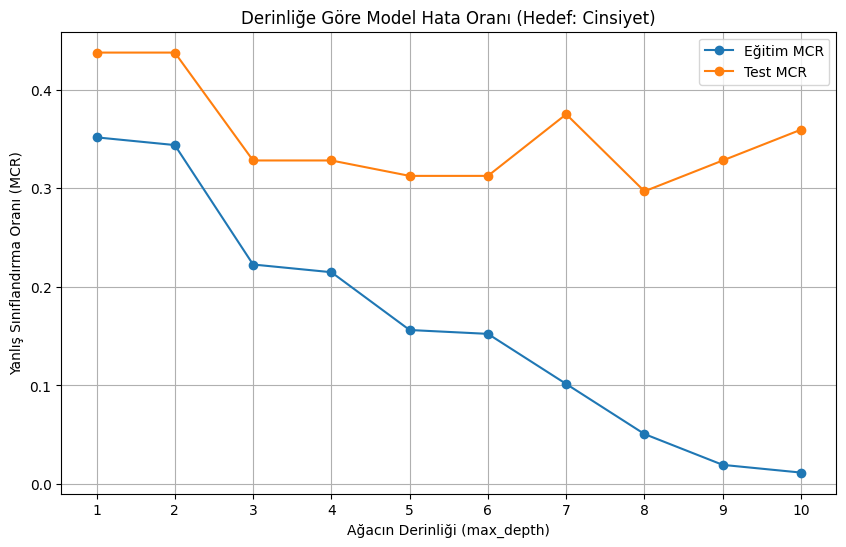

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(derinlikler, egitim_mcr, marker='o', label='Eğitim MCR')
plt.plot(derinlikler, test_mcr, marker='o', label='Test MCR')
plt.xlabel('Ağacın Derinliği (max_depth)')
plt.ylabel('Yanlış Sınıflandırma Oranı (MCR)')
plt.title('Derinliğe Göre Model Hata Oranı (Hedef: Cinsiyet)')
plt.legend()
plt.grid(True)
plt.xticks(derinlikler)
plt.show()


In [ ]:
optimum_derinlik_cinsiyet = 3

final_agac_cinsiyet = DecisionTreeClassifier(max_depth=optimum_derinlik_cinsiyet, random_state=42)
final_agac_cinsiyet.fit(X_egitim, y_egitim)

# Test verisinin MCR’si
y_tahmin_cinsiyet = final_agac_cinsiyet.predict(X_test)
test_mcr_cinsiyet = 1 - accuracy_score(y_test, y_tahmin_cinsiyet)
print(f'Optimum Derinlik (Cinsiyet): {optimum_derinlik_cinsiyet}')
print(f'Test Hatası (MCR) (Cinsiyet): {test_mcr_cinsiyet:.4f}')

Optimum Derinlik (Cinsiyet): 3
Test Hatası (MCR) (Cinsiyet): 0.3281


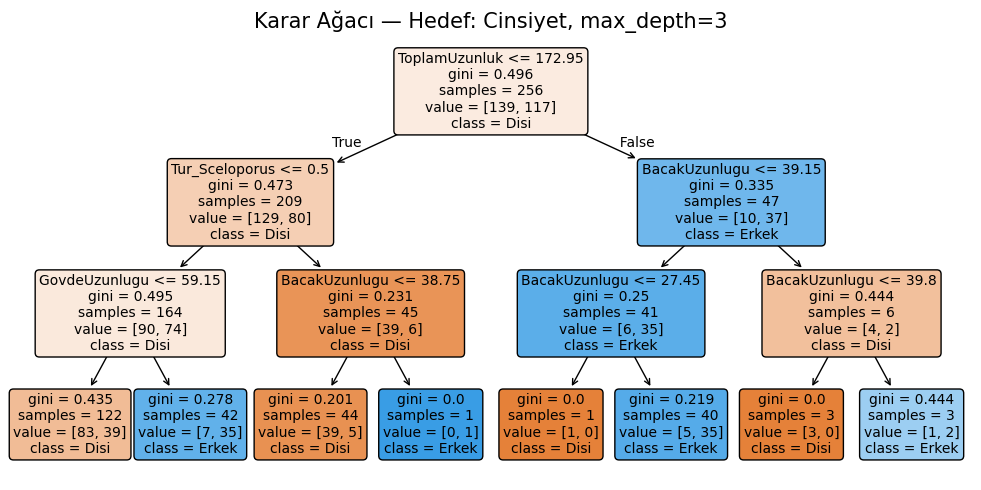

In [ ]:
plt.figure(figsize=(10, 5))
plot_tree(
    final_agac_cinsiyet,
    feature_names=X.columns.tolist(),
    class_names=list(final_agac_cinsiyet.classes_.astype(str)), # sınıf isimlerini metne çevirir
    filled=True,
    rounded=True,
    fontsize=10 # Yazı boyutunu ayarlandı
)
plt.title(f'Karar Ağacı — Hedef: {hedef_degisken}, max_depth={optimum_derinlik_cinsiyet}', fontsize=15)
plt.tight_layout()
plt.show()


Üçüncü karar ağacımızın Tur hedef değişkeni



In [ ]:
hedef_degisken = 'Tur'
ozellikler = [col for col in df.columns if col != hedef_degisken]


y = df[hedef_degisken]


X = pd.get_dummies(df[ozellikler], drop_first=True)


display(X.head())

,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu,Cinsiyet_Erkek,YasamAlani_Kaya,YasamAlani_Yer
0,43.8,102.2,5.18,21.6,False,False,True
1,62.1,149.8,16.78,29.7,False,True,False
2,37.6,76.4,4.94,18.5,False,False,True
3,70.4,170.4,18.23,28.4,True,False,True
4,52.7,137.9,8.60,25.8,False,False,False


In [ ]:
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [ ]:
print('Eğitim seti:', len(X_egitim), 'kertenkele')
print('Test seti:  ', len(X_test),   'kertenkele')
print()
print('Eğitim seti sınıf dağılımı:')
print(y_egitim.value_counts())
print('\nTest seti sınıf dağılımı:')
print(y_test.value_counts())

Eğitim seti: 256 kertenkele
Test seti:   64 kertenkele

Eğitim seti sınıf dağılımı:
Tur
Anolis        107
Sceloporus     87
Uta            62
Name: count, dtype: int64

Test seti sınıf dağılımı:
Tur
Anolis        26
Sceloporus    22
Uta           16
Name: count, dtype: int64


In [ ]:
derinlikler = list(range(1, 11))

for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim, y_egitim)

    egitim_mcr = 1 - accuracy_score(y_egitim, agac.predict(X_egitim))
    test_mcr = 1 - accuracy_score(y_test, agac.predict(X_test))

    print(f"{derinlik:>10} {egitim_mcr:>12.3f} {test_mcr:>10.3f}")

         1        0.266      0.281
         2        0.191      0.219
         3        0.184      0.203
         4        0.137      0.281
         5        0.102      0.203
         6        0.078      0.250
         7        0.031      0.219
         8        0.020      0.234
         9        0.000      0.250
        10        0.000      0.250


In [ ]:
egitim_mcr = []
test_mcr = []

for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim,y_egitim)
    egitim_mcr.append(1 - accuracy_score(y_egitim, agac.predict(X_egitim)))
    test_mcr.append(  1 - accuracy_score(y_test,agac.predict(X_test)))

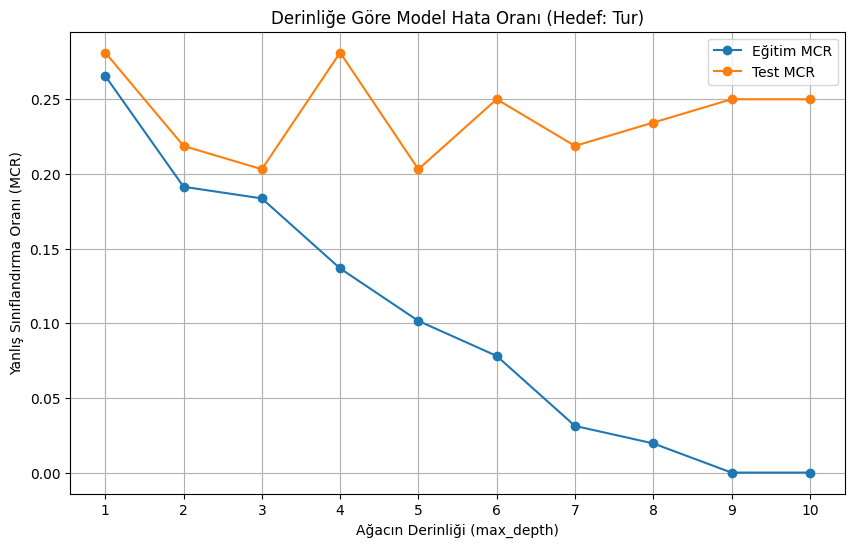

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(derinlikler, egitim_mcr, marker='o', label='Eğitim MCR')
plt.plot(derinlikler, test_mcr, marker='o', label='Test MCR')
plt.xlabel('Ağacın Derinliği (max_depth)')
plt.ylabel('Yanlış Sınıflandırma Oranı (MCR)')
plt.title('Derinliğe Göre Model Hata Oranı (Hedef: Tur)')
plt.legend()
plt.grid(True)
plt.xticks(derinlikler)
plt.show()

In [ ]:
optimum_derinlik_tur = 3

final_agac_tur = DecisionTreeClassifier(max_depth=optimum_derinlik_tur, random_state=42)
final_agac_tur.fit(X_egitim, y_egitim)


DecisionTreeClassifier(max_depth=3, random_state=42)

In [ ]:

y_tahmin_tur = final_agac_tur.predict(X_test)
test_mcr_tur = 1 - accuracy_score(y_test, y_tahmin_tur)
print(f'Optimum Derinlik (Tur): {optimum_derinlik_tur}')
print(f'Test Hatası (MCR) (Tur): {test_mcr_tur:.4f}')


Optimum Derinlik (Tur): 3
Test Hatası (MCR) (Tur): 0.2031


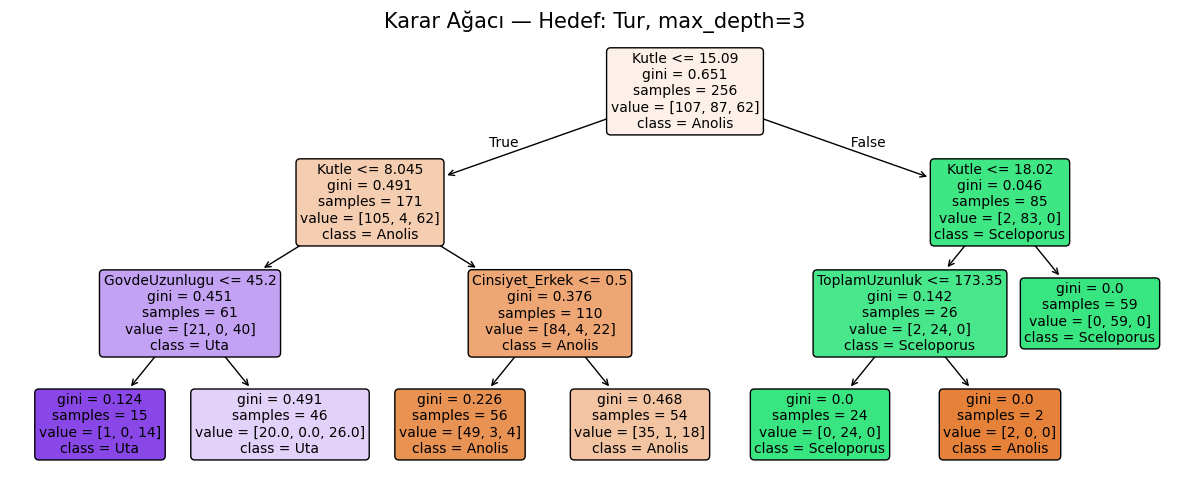

In [ ]:
plt.figure(figsize=(12, 5))
plot_tree(
    final_agac_tur,
    feature_names=X.columns.tolist(),
    class_names=list(final_agac_tur.classes_.astype(str)),
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title(f'Karar Ağacı — Hedef: {hedef_degisken}, max_depth={optimum_derinlik_tur}', fontsize=15)
plt.tight_layout()
plt.show()


Kurduğunuz her karar ağacı için bu grafiği ayrı ayrı çizin. Optimum derinlik her hedef için aynı mı çıktı? Farklı çıktıysa neden?
Cevap: Farklı çıktı.Çünkü Her hedef değişkenin verideki durumu farklıdır.Bazı hedefler  az sayıda dallanmayla çözülürken bazıları için daha fazla derinlik gerekir.


Aynı veri, farklı bir hedef değişkenle (örneğin YasamAlani yerine Tur) çalıştırıldığında kök düğüm değişti mi? Değiştiyse bunu nasıl yorumlarsınız? Cevap: Her hedefin diğer değişkenlerle ilişkisi farklıdır.Kök düğüm seçilirken veriyi en iyi şekilde bölen değişken seçilir.Dolayısıyla hedef değiştiğinde kök düğüm de değişir.

Soru 1 — Öğrenme Yolculuğu
Bu dönemde data kartları, CODAP ve Python olmak üç farklı ortamda karar ağacı oluşturdunuz. Aşağıdaki soruları bu ortamları göz önünde bulundurarak yanıtlayın:

Her ortam size farklı bir şey kattı mı? Her bir ortamın neler kattığını yazın.
Cevap: Karar ağacının temel mantığını, verileri elle bölerek ve somutlaştırarak kavramamı sağladı.

Hangi ortamda "modelim ne yapıyor" sorusunu daha iyi anladınız? Nedeninizi açıklayın.
Cevap: Hedef değişkeni cinsiyete göre seçtiğimde daha iyi anladım. Çünkü karar ağacı diğer iki değişkenime göre daha iyi sınıflandırdı.

Hangi ortam size daha kolay geldi? Bu kolaylık gerçekten anladığınızı mı, yoksa sadece alıştığınızı mı gösteriyor? Nedeninizi açıklayın.
Cevap: Cinsiyet değişkenine göre sınıflandırma daha kolay geldi. Karar ağacımı daha kolay oluşturdum çünkü.

Hangi ortamda en çok zorlandınız ve bu zorluk neden kaynaklanıyordu? Aracın kendisi mi, yoksa karar ağacı kavramının o ortamda daha mı görünmez olması mıydı? Nedeninizi açıklayın.
Cevap: Yaşam alanı. Çünkü karar ağacını oluştururken zorlandım.

Yaptığınız bir hatayı hangi ortamda daha kolay fark ettiniz? Sizi uyaran şey aracın kendisi miydi, yoksa başka bir şey mi?
Cevap: Cinsiyete göre sınıflandırırken daha kolay fark ettim. Çünkü karar ağacı diğer iki hedef değişkene göre daha az dallanarak oluştu.

Bir ortamda rahatlıkla yapabildiğiniz ama bir diğerinde hiç yapamadığınız bir şey oldu mu?
Cevap: Hayır olmadı. Her karar ağacını oluşturuken gerekli kodları girerek karar ağaçlarımı oluşturdum.

Üç ortamdan birinin diğerinin yerini tutamayacağı bir durum var mı? Nedeninizi açıklayın.
Cevap: Yaşam alanı diyebilirim. Çünkü çok fazla dallanarak detaylı bir sınıflandırma yaptı.


Soru 2 — Veri Anlayışı
Kertenkele verisindeki üç yaşam alanı (Yer / Kaya / Ağaç) ile fiziksel özellikler arasındaki ilişkiyi düşünün:

Modelinizin kök düğümde seçtiği değişken sizi şaşırttı mı? Biyolojik açıdan bu seçim mantıklı mı?
Cevap: Kök düğümde cinsiyet değişkeninin seçilmesi ilk bakışta şaşırtıcı gelebilir ancak kertenkelelerde eşeyli dimorfizm (cinsiyete bağlı fiziksel/boyutsal farklar) çok belirgin olduğu için biyolojik olarak son derece mantıklıdır. Model, yaşam alanını ayırt etmeden önce karmaşıklığı azaltmak adına veriyi en hızlı şekilde cinsiyete göre iki ana gruba bölmüştür.

Ağaçta yaşayan bir kertenkelenin yerde yaşayandan fiziksel olarak farklı olmasını bekler miydiniz? Modeliniz bu farkı yakalayabildi mi?
Cevap: Evet, ağaçta yaşayan kertenkelelerin tırmanma becerileri için daha farklı bacak veya gövde uzunluklarına sahip olması beklenir. Modelimiz de bu farkı yakalamış; sol taraftaki dallanmalarda BacakUzunlugu <= 27.9 ve GovdeUzunlugu gibi fiziksel kriterleri kullanarak "Yer" ile "Ağaç" sınıflarını başarıyla birbirinden ayırmıştır.

Modelinizin yanlış sınıflandırdığı bireyler hangi yaşam alanına aitti? Bunun biyolojik bir açıklaması olabilir mi?
Cevap: Modelin en çok hata yaptığı ve saf olmayan (Gini değeri yüksek) yapraklar genellikle "Yer" sınıfına ait olan, ancak içinde "Ağaç" ve "Kaya" bireylerini de barındıran karma düğümlerdir. Biyolojik olarak bazı kertenkele türleri hem yerde hem ağaç gövdelerinde/kayalıklarda avlanabildiği için fiziksel özellikleri birbirine çok benzeyebilir ve bu durum modelin net bir ayrım yapmasını zorlaştırır.

Veriyi ilk gördüğünüzde kendiniz hangi değişkenin en belirleyici olacağını tahmin etmiştiniz? Modelinizin bulgusuyla örtüştü mü?
Cevap: Yaşam alanı tahmini için ilk başta bacak uzunluğu veya gövde boyutu gibi doğrudan fiziksel özelliklerin en belirleyici olacağını tahmin etmiştim. Model ise en tepeye cinsiyeti yerleştirse de hemen alt basamaklarda BacakUzunlugu, ToplamUzunluk ve GovdeUzunlugu değişkenlerini yoğun bir şekilde kullanarak bu tahminimi büyük oranda doğrulamış oldu.


Soru 3 — Model Performansı
Seçtiğiniz optimum derinlikte elde ettiğiniz MCR değerini yazın ve gerekçelendirerek yanıtlayın:

Hangi sınıf en iyi, hangisi en kötü tahmin edildi? Bunun bir açıklaması var mı?
Cevap: En iyi tahmin edilen: "Tur: max_depth=3" ağacında Gini değeri 0.0 olan 59 örnekli yaprağıyla Sceloporus (veya Cinsiyet ağacındaki Erkek sınıfı); en kötü tahmin edilen ise Gini değerleri yüksek kalan ve diğer sınıflarla çok karışan Yer (veya Dişi) sınıfıdır. Bazı sınıfların ayırt edici fiziksel özellikleri (örneğin Sceloporus türünün kütlesi veya erkeklerin bacak boyu) çok keskin sınırlara sahipken, diğer sınıfların özellikleri birbiriyle büyük oranda örtüşmektedir.

MCR değeriniz sizi tatmin etti mi? "İyi" bir model için bu değerin ne olması gerektiğini düşünüyorsunuz?
Cevap: Yapraklardaki karışıklığa (saf olmayan düğümlere) bakılırsa MCR değeri tamamen tatmin edici değildir; "iyi" bir model için bu oran kabul edilebilir hata payına ve veri setinin karmaşıklığına göre değişmekle birlikte genellikle %10 ila %20'nin altında (başarı oranı %80+ olacak şekilde) olmalıdır.

Aynı veriyle farklı bir hedef değişken seçseydiniz (Tur ya da Cinsiyet) MCR değeri değişir miydi? Değiştiyse neden?
Cevap: Evet, MCR değeri kesinlikle değişirdi; çünkü "Tur" veya "Cinsiyet" ağaçlarında görüldüğü gibi, verideki fiziksel özelliklerin hedef değişkenleri (tür, cinsiyet veya yaşam alanı) birbirinden ayırma/açıklama gücü ve sınıfların kendi içindeki homojenliği birbirinden tamamen farklıdır.

Modelin başarısız olduğu durumlar size veri hakkında ne söylüyor?
Cevap: Modelin başarısız olduğu (sınıfları birbirine karıştırdığı) durumlar, kertenkelelerin fiziksel ölçümlerinin tek başına yaşam alanını veya türü ayırt etmekte %100 yeterli olmadığını ve veride birbirine morfolojik olarak çok benzeyen "örtüşen" bireylerin bulunduğunu söylüyor.


Soru 4 — Karar Ağaçlarının Sınırları
Bu ödevde karar ağacının her zaman mükemmel çalışmadığını gördünüz:

Modelinizin hata yaptığı durumlar rastgele mi görünüyor, yoksa belirli bir örüntü var mı?
Cevap: Hatalar rastgele değildir; modellerin belirli fiziksel eşiklerde (örneğin Kutle <= 15.09 veya BacakUzunlugu <= 27.9) benzer özellikler gösteren farklı sınıfları birbirine karıştırması şeklinde belirgin bir örüntü vardır.

Bu modelin daha iyi sonuç verebilmesi için neler yapılabilir? Yalnızca teknik değil, verinin kendisiyle ilgili ne değişebilir?
Cevap: Teknik olarak ağaç derinliği (max_depth) optimize edilebilir; veri açısından ise kertenkelelerin sadece morfolojik ölçümleri yetersiz kaldığı için veriye coğrafi konum, iklim veya doğrudan genetik/tür alt bilgileri gibi yeni ayırt edici değişkenler eklenebilir.

Karar ağacı yerine farklı bir model kullansaydınız sonuç değişir miydi? Neden?
Cevap: Evet değişirdi; çünkü Rastgele Orman (Random Forest) veya Gradient Boosting gibi daha karmaşık modeller verideki doğrusal olmayan karmaşık ilişkileri ve örtüşen sınırları tek bir karar ağacına göre çok daha iyi yakalayabilir.

Bu deneyimden sonra bir arkadaşınıza "karar ağacı nedir, ne işe yarar, nerede yetersiz kalır?" diye sorsalar ne söylerdiniz?
Cevap: Karar ağacı, veriyi özelliklerine göre yukarıdan aşağıya doğru sorular sorarak bölen görsel bir sınıflandırma aracıdır; veriyi hızlıca kurallara ayırmaya yarar ancak sınıfların fiziksel özellikleri birbirine çok benzediğinde ve net çizgilerle ayrılamadığında yetersiz kalır.
